In [ ]:
import os
import subprocess

# FIX (Kaggle): don't hardcode "0,1" -- Kaggle usually gives 1 or 2 GPUs, and
# forcing device 1 to exist when it doesn't causes a CUDA init error. Detect
# what's actually available instead.
try:
    _n_visible = len(subprocess.run(
        ["nvidia-smi", "--query-gpu=index", "--format=csv,noheader"],
        capture_output=True, text=True, check=True).stdout.strip().splitlines())
except Exception:
    _n_visible = 0
if _n_visible > 0:
    os.environ["CUDA_VISIBLE_DEVICES"] = ",".join(str(i) for i in range(_n_visible))
    print(f"Detected {_n_visible} GPU(s), CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']}")
else:
    print("No GPU detected via nvidia-smi -- leaving CUDA_VISIBLE_DEVICES unset.")

Detected 2 GPU(s), CUDA_VISIBLE_DEVICES=0,1


In [ ]:
# ============================================================================
# CELL 1 — ENVIRONMENT (PyTorch). RUN FIRST, IN A FRESH KERNEL.
#
# PORTING NOTE: the old CELL 1 hunted for CUDA `libdevice` because TensorFlow's
# XLA JIT needs it at runtime. PyTorch ships its own precompiled CUDA kernels
# in the wheel, so that entire problem disappears -- there is nothing to find
# and nothing to point XLA at.
#
# What IS worth setting before `import torch` is the caching-allocator config.
# `expandable_segments` lets the allocator grow a segment instead of reserving
# a new one, which markedly reduces fragmentation OOMs when you train several
# ablation variants back-to-back in one kernel (exactly what CELL 18 does).
# Like XLA_FLAGS, it is read ONCE at first torch import -- edit it after that
# and you must restart the kernel.
# ============================================================================
import os

# ---------------------------------------------------------------------------
# DEBUG_CUDA: turn this on the moment you hit any CUDA-level error
# ("misaligned address", "illegal memory access", "device-side assert").
# CUDA kernels launch asynchronously, so by default the Python traceback points
# at whatever call happened to synchronise NEXT -- almost never the real culprit.
# CUDA_LAUNCH_BLOCKING=1 makes every launch synchronous, so the traceback lands
# on the actual failing operation. It costs maybe 10-30% throughput, so turn it
# back off once you have located the problem.
# Like the allocator config, this is read at first torch import: set it here,
# then Kernel > Restart and run from the top.
# ---------------------------------------------------------------------------
DEBUG_CUDA = False

if DEBUG_CUDA:
    os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
    os.environ["TORCH_SHOW_CPP_STACKTRACES"] = "1"
else:
    os.environ.pop("CUDA_LAUNCH_BLOCKING", None)

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # needed if you ever
                                                              # enable deterministic algos
os.environ.setdefault("OMP_NUM_THREADS", "8")

print("Env configured for PyTorch:")
for k in ("PYTORCH_CUDA_ALLOC_CONF", "CUBLAS_WORKSPACE_CONFIG", "OMP_NUM_THREADS"):
    print(f"  {k} = {os.environ[k]}")
print(f"  DEBUG_CUDA = {DEBUG_CUDA}"
      f"{'  <- synchronous launches, tracebacks are trustworthy' if DEBUG_CUDA else ''}")
print("\nNo libdevice / XLA_FLAGS needed -- PyTorch does not JIT-compile via NVVM.")


Env configured for PyTorch:
  PYTORCH_CUDA_ALLOC_CONF = expandable_segments:True
  CUBLAS_WORKSPACE_CONFIG = :4096:8
  OMP_NUM_THREADS = 8
  DEBUG_CUDA = False

No libdevice / XLA_FLAGS needed -- PyTorch does not JIT-compile via NVVM.


In [ ]:
# ============================================================================
# CELL 2 — PART 1: CONFIG & DATASET DISCOVERY
# Unchanged from the TF version: this cell is pure numpy / OpenCV / sklearn and
# has no framework dependency.
#
# PORTING NOTE: the old comment here warned that importing torch stole ~11 GB
# of GPU:0 from TensorFlow. That no longer applies -- torch IS the framework
# now, and it is imported deliberately in CELL 8. Part 1 still does not import
# it, so you can run Part 1 alone without ever creating a CUDA context.
# ============================================================================
import os, re, gc, json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
sns.set_style("whitegrid")
cv2.setNumThreads(4)

# # --- ONE place for every path used by all four parts -----------------------
# # FIX (Kaggle): download the dataset via kagglehub, outputs go to /kaggle/working
# try:
#     import kagglehub
# except ImportError:
#     import subprocess, sys
#     subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
#     import kagglehub

DATA_ROOT      = "/media/dhrubo/New Volume/TDN"

PROJECT_ROOT   = "/media/dhrubo/New Volume/TDN"
DATA_DIR       = f"{PROJECT_ROOT}/processed_data"
CHECKPOINT_DIR = f"{PROJECT_ROOT}/checkpoints"
FIGURE_DIR     = f"{PROJECT_ROOT}/paper_figures"
for _d in (DATA_DIR, CHECKPOINT_DIR, FIGURE_DIR):
    os.makedirs(_d, exist_ok=True)

RESOLUTIONS_TO_BUILD = [256, 512]
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")


def _has_token(text, token):
    return re.search(r"(?<![a-z])" + token + r"(?![a-z])", text) is not None


def discover_dataset(root):
    candidates = {"ct_tumor": [], "ct_healthy": [], "mri_tumor": [], "mri_healthy": []}
    root = os.path.abspath(root)
    for dirpath, _, filenames in os.walk(root):
        if not any(f.lower().endswith(IMG_EXT) for f in filenames):
            continue
        rel = os.path.relpath(dirpath, root).lower()
        is_ct, is_mri = _has_token(rel, "ct"), _has_token(rel, "mri")
        is_tumor = _has_token(rel, "tumou?r")
        is_healthy = _has_token(rel, "healthy") or _has_token(rel, "normal") or "no_tumor" in rel
        if is_ct and is_tumor and not is_healthy:      candidates["ct_tumor"].append(dirpath)
        elif is_ct and is_healthy:                      candidates["ct_healthy"].append(dirpath)
        elif is_mri and is_tumor and not is_healthy:    candidates["mri_tumor"].append(dirpath)
        elif is_mri and is_healthy:                     candidates["mri_healthy"].append(dirpath)
    return candidates


assert os.path.isdir(DATA_ROOT), f"DATA_ROOT does not exist: {DATA_ROOT}"
found = discover_dataset(DATA_ROOT)

CT_TUMOR_DIR    = found["ct_tumor"][0]    if found["ct_tumor"]    else None
CT_HEALTHY_DIR  = found["ct_healthy"][0]  if found["ct_healthy"]  else None
MRI_TUMOR_DIR   = found["mri_tumor"][0]   if found["mri_tumor"]   else None
MRI_HEALTHY_DIR = found["mri_healthy"][0] if found["mri_healthy"] else None

DIRS = [CT_TUMOR_DIR, CT_HEALTHY_DIR, MRI_TUMOR_DIR, MRI_HEALTHY_DIR]
USE_REAL_DATA = all(DIRS) and all(os.path.isdir(p) for p in DIRS)

if USE_REAL_DATA:
    print("Auto-discovered dataset paths:")
    for k, v in found.items():
        n = len([f for f in os.listdir(v[0]) if f.lower().endswith(IMG_EXT)])
        print(f"  {k:12s} -> {v[0]}  ({n} images)")
else:
    print("Could not locate all four folders:", {k: bool(v) for k, v in found.items()})

print(f"\nReal dataset usable: {USE_REAL_DATA}")
print("Output directory   :", DATA_DIR)


Auto-discovered dataset paths:
  ct_tumor     -> /media/dhrubo/New Volume/TDN/Dataset/Brain Tumor CT scan Images/Tumor  (2318 images)
  ct_healthy   -> /media/dhrubo/New Volume/TDN/Dataset/Brain Tumor CT scan Images/Healthy  (2300 images)
  mri_tumor    -> /media/dhrubo/New Volume/TDN/Dataset/Brain Tumor MRI images/Tumor  (3000 images)
  mri_healthy  -> /media/dhrubo/New Volume/TDN/Dataset/Brain Tumor MRI images/Healthy  (2000 images)

Real dataset usable: True
Output directory   : /media/dhrubo/New Volume/TDN/processed_data


In [ ]:
# ============================================================================
# CELL 3 — PREPROCESSING  (framework-independent, unchanged)
# Storage stays uint8 (4x less RAM). The /255 normalisation happens exactly
# once, on the GPU, inside the training/eval code in Part 3.
# ============================================================================
def preprocess_image(img_gray, target_size):
    """Resize + CLAHE + NLM denoise. Returns uint8 HxWx1 in [0,255]."""
    img_gray = cv2.resize(img_gray, (target_size, target_size))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_gray = clahe.apply(img_gray)
    img_gray = cv2.fastNlMeansDenoising(img_gray, h=7)
    return img_gray[..., np.newaxis]


def load_images_from_folder(folder, target_size, limit=None):
    images, names, raw_first = [], [], None
    filenames = sorted(f for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))
    if limit is not None:
        filenames = filenames[:limit]
    for filename in filenames:
        img = cv2.imread(os.path.join(folder, filename), cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        if raw_first is None:
            raw_first = cv2.resize(img, (target_size, target_size))
        images.append(preprocess_image(img, target_size))
        names.append(filename)
    return np.array(images, dtype="uint8"), names, raw_first


def pair_modalities(ct_imgs, mri_imgs, label, seed=42):
    """Truncate to min(len) after a shuffle, so every source image is used at
    most once -- no duplicate landing in both train and test.

    NOTE FOR THE PAPER: this removes image-level leakage only. The four folders
    are independent patient sets, so CT and MRI in a pair are NOT the same
    patient. State this explicitly in Methods -- it constrains what the
    alignment module (N3) can be claimed to do.
    """
    rng = np.random.default_rng(seed)
    n = min(len(ct_imgs), len(mri_imgs))
    ct_idx  = rng.permutation(len(ct_imgs))[:n]
    mri_idx = rng.permutation(len(mri_imgs))[:n]
    return ct_imgs[ct_idx], mri_imgs[mri_idx], np.full((n, 1), label, dtype="float32")


print("Preprocessing functions ready (uint8 storage, non-duplicating pairing).")


Preprocessing functions ready (uint8 storage, non-duplicating pairing).


     Category  Count
   CT — Tumor   2318
 CT — Healthy   2300
  MRI — Tumor   3000
MRI — Healthy   2000


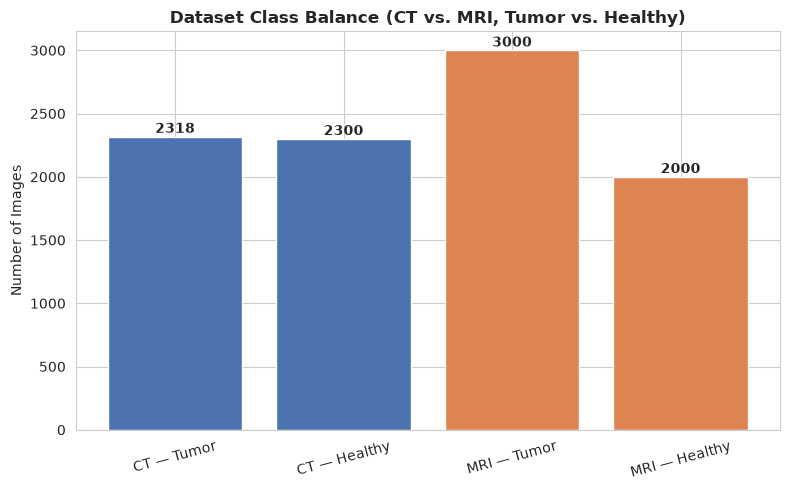

In [ ]:
# ============================================================================
# CELL 4 — CLASS BALANCE FIGURE
# ============================================================================
counts = {
    "CT — Tumor":    len([f for f in os.listdir(CT_TUMOR_DIR)    if f.lower().endswith(IMG_EXT)]),
    "CT — Healthy":  len([f for f in os.listdir(CT_HEALTHY_DIR)  if f.lower().endswith(IMG_EXT)]),
    "MRI — Tumor":   len([f for f in os.listdir(MRI_TUMOR_DIR)   if f.lower().endswith(IMG_EXT)]),
    "MRI — Healthy": len([f for f in os.listdir(MRI_HEALTHY_DIR) if f.lower().endswith(IMG_EXT)]),
}
counts_df = pd.DataFrame(list(counts.items()), columns=["Category", "Count"])
print(counts_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(counts_df["Category"], counts_df["Count"],
              color=["#4C72B0", "#4C72B0", "#DD8452", "#DD8452"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + max(counts.values()) * 0.01,
            str(int(b.get_height())), ha="center", fontweight="bold")
ax.set_ylabel("Number of Images")
ax.set_title("Dataset Class Balance (CT vs. MRI, Tumor vs. Healthy)", fontweight="bold")
plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/fig1a_class_balance.png", dpi=200); plt.show()
counts_df.to_csv(f"{DATA_DIR}/class_balance.csv", index=False)


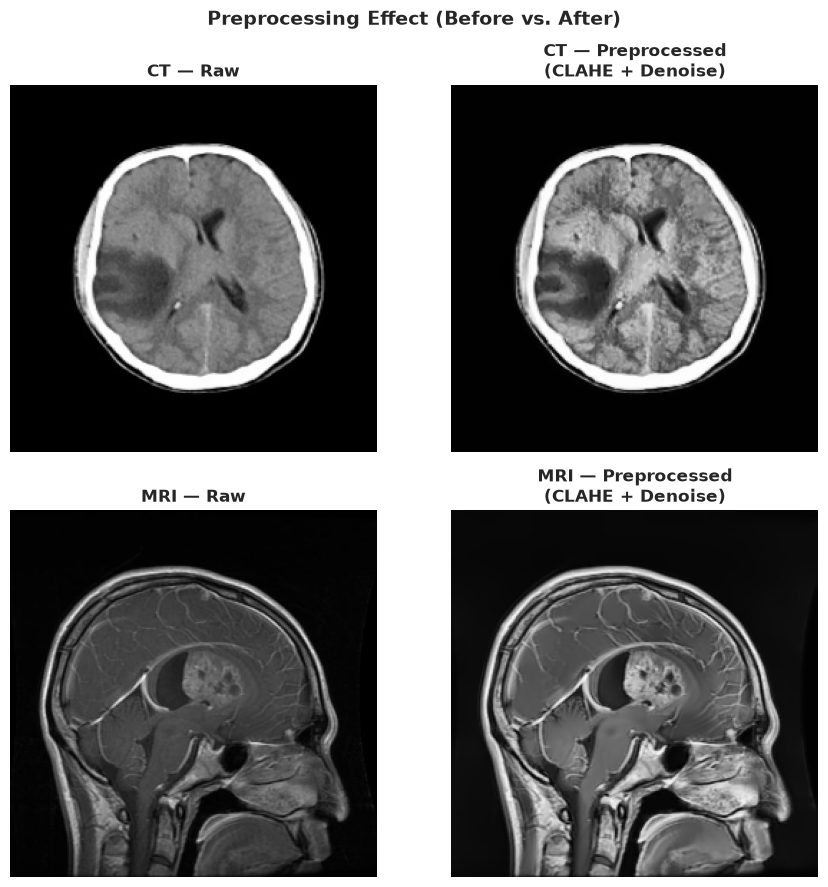

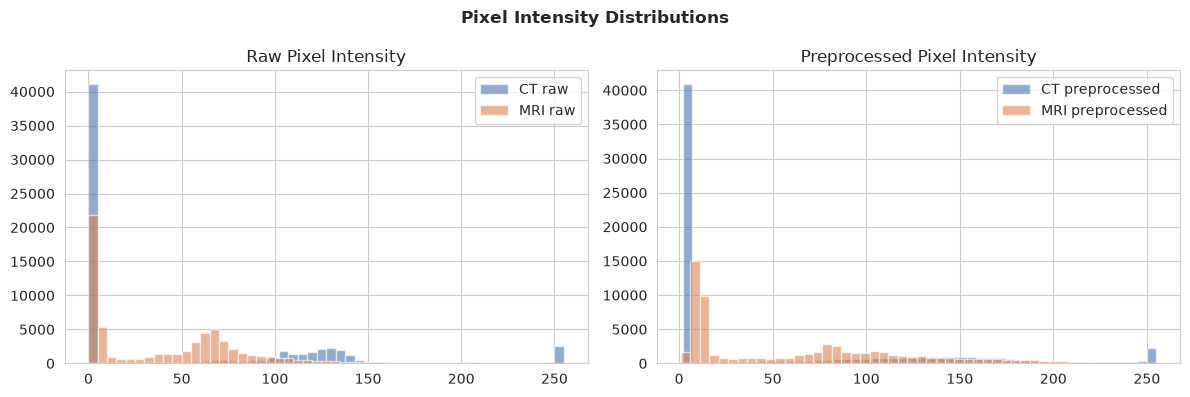

In [ ]:
# ============================================================================
# CELL 5 — PREPROCESSING DEMO FIGURE
# ============================================================================
demo_res = RESOLUTIONS_TO_BUILD[0]
_, _, raw_ct  = load_images_from_folder(CT_TUMOR_DIR,  demo_res, limit=1)
_, _, raw_mri = load_images_from_folder(MRI_TUMOR_DIR, demo_res, limit=1)

proc_ct  = preprocess_image(raw_ct,  demo_res).squeeze()
proc_mri = preprocess_image(raw_mri, demo_res).squeeze()

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, img, t in zip(axes.ravel(), [raw_ct, proc_ct, raw_mri, proc_mri],
                      ["CT — Raw", "CT — Preprocessed\n(CLAHE + Denoise)",
                       "MRI — Raw", "MRI — Preprocessed\n(CLAHE + Denoise)"]):
    ax.imshow(img, cmap="gray"); ax.set_title(t, fontweight="bold"); ax.axis("off")
plt.suptitle("Preprocessing Effect (Before vs. After)", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig1b_preprocessing.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw_ct.ravel(),  bins=50, alpha=.6, label="CT raw",  color="#4C72B0")
axes[0].hist(raw_mri.ravel(), bins=50, alpha=.6, label="MRI raw", color="#DD8452")
axes[0].set_title("Raw Pixel Intensity"); axes[0].legend()
axes[1].hist(proc_ct.ravel(),  bins=50, alpha=.6, label="CT preprocessed",  color="#4C72B0")
axes[1].hist(proc_mri.ravel(), bins=50, alpha=.6, label="MRI preprocessed", color="#DD8452")
axes[1].set_title("Preprocessed Pixel Intensity"); axes[1].legend()
plt.suptitle("Pixel Intensity Distributions", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig1c_histograms.png", dpi=200); plt.show()


In [ ]:
# ============================================================================
# CELL 6 — BUILD DATASETS  (
# The train/val/test split is computed ONCE and written to disk, so Part 3 and
# Part 4 provably evaluate on the same test set.
#
# STORAGE LAYOUT NOTE: the .npy files stay NHWC (N, H, W, 1), exactly as in the
# TF version. PyTorch wants NCHW, but the permutation is done at the tensor
# boundary in Part 3 -- so these arrays, and any you already generated with the
# TF notebook, remain byte-for-byte reusable. Do not re-run Part 1 if you have
# already built them.
# ============================================================================
def build_dataset(target_size):
    ct_tumor,    _, _ = load_images_from_folder(CT_TUMOR_DIR,    target_size)
    ct_healthy,  _, _ = load_images_from_folder(CT_HEALTHY_DIR,  target_size)
    mri_tumor,   _, _ = load_images_from_folder(MRI_TUMOR_DIR,   target_size)
    mri_healthy, _, _ = load_images_from_folder(MRI_HEALTHY_DIR, target_size)

    a_t, b_t, y_t = pair_modalities(ct_tumor,   mri_tumor,   label=1)
    a_h, b_h, y_h = pair_modalities(ct_healthy, mri_healthy, label=0)

    A = np.concatenate([a_t, a_h]); B = np.concatenate([b_t, b_h]); Y = np.concatenate([y_t, y_h])
    # uint8-safe mean. NOTE: this "reference" is just the average of the two
    # inputs -- see CELL 16, where reference-free fusion metrics are the
    # headline numbers and SSIM-vs-mean is demoted to a sanity check.
    REF = ((A.astype("uint16") + B.astype("uint16")) // 2).astype("uint8")

    del ct_tumor, ct_healthy, mri_tumor, mri_healthy, a_t, b_t, a_h, b_h
    gc.collect()
    print(f"[{target_size}] A={A.shape} B={B.shape} Y={Y.shape} "
          f"(tumor={int(Y.sum())}, healthy={int((1-Y).sum())}) dtype={A.dtype}")
    return A, B, Y, REF


datasets = {}
for res in RESOLUTIONS_TO_BUILD:
    print(f"\n--- Building {res}x{res} ---")
    A, B, Y, REF = build_dataset(res)
    np.save(f"{DATA_DIR}/A_{res}.npy", A)
    np.save(f"{DATA_DIR}/B_{res}.npy", B)
    np.save(f"{DATA_DIR}/Y_{res}.npy", Y)
    np.save(f"{DATA_DIR}/REF_{res}.npy", REF)
    print(f"Saved to {DATA_DIR}")

    if res == RESOLUTIONS_TO_BUILD[0]:
        datasets[res] = (A, B, Y, REF)          # keep smallest for the demo figure
        idx = np.arange(len(Y))
        tr, te = train_test_split(idx, test_size=0.2,  stratify=Y,     random_state=42)
        tr, va = train_test_split(tr,  test_size=0.15, stratify=Y[tr], random_state=42)
        np.savez(f"{DATA_DIR}/split_indices.npz", train=tr, val=va, test=te)
        print(f"Canonical split saved: train={len(tr)} val={len(va)} test={len(te)}")
    else:
        datasets[res] = (None, None, Y, None)
        del A, B, REF
    gc.collect()

with open(f"{DATA_DIR}/config.txt", "w") as f:
    f.write(f"RESOLUTIONS={RESOLUTIONS_TO_BUILD}\nUSE_REAL_DATA={USE_REAL_DATA}\n")



--- Building 256x256 ---
[256] A=(4318, 256, 256, 1) B=(4318, 256, 256, 1) Y=(4318, 1) (tumor=2318, healthy=2000) dtype=uint8
Saved to /media/dhrubo/New Volume/TDN/processed_data
Canonical split saved: train=2935 val=519 test=864

--- Building 512x512 ---
[512] A=(4318, 512, 512, 1) B=(4318, 512, 512, 1) Y=(4318, 1) (tumor=2318, healthy=2000) dtype=uint8
Saved to /media/dhrubo/New Volume/TDN/processed_data


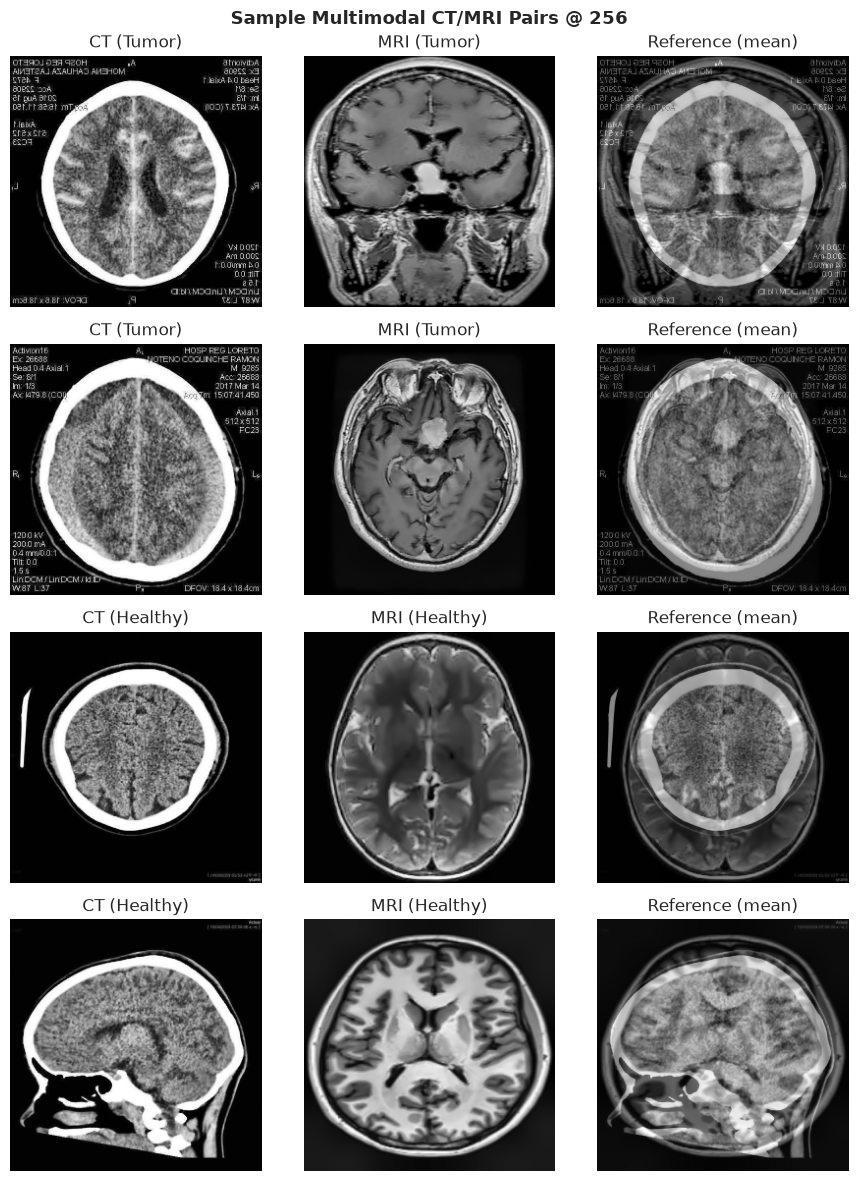

Table 1 — Dataset Split Summary
            Train  Val  Test  Train Tumor%  Test Tumor%
Resolution                                             
256x256      2935  519   864          53.7         53.7
512x512      2935  519   864          53.7         53.7

Part 1 complete.


In [ ]:
# ============================================================================
# CELL 7 — SAMPLE PAIRS + SPLIT SUMMARY  (unchanged)
# ============================================================================
show_res = RESOLUTIONS_TO_BUILD[0]
A, B, Y, REF = datasets[show_res]
_sp = np.load(f"{DATA_DIR}/split_indices.npz")
train_idx, val_idx, test_idx = _sp["train"], _sp["val"], _sp["test"]

rng = np.random.default_rng(1)
sample_idx = np.concatenate([
    rng.choice(np.where(Y.ravel() == 1)[0], size=2, replace=False),
    rng.choice(np.where(Y.ravel() == 0)[0], size=2, replace=False),
])

fig, axes = plt.subplots(len(sample_idx), 3, figsize=(9, 3 * len(sample_idx)))
for r, i in enumerate(sample_idx):
    lab = "Tumor" if Y[i, 0] == 1 else "Healthy"
    for c, (img, t) in enumerate([(A[i], f"CT ({lab})"), (B[i], f"MRI ({lab})"),
                                  (REF[i], "Reference (mean)")]):
        axes[r, c].imshow(img.squeeze(), cmap="gray"); axes[r, c].set_title(t); axes[r, c].axis("off")
plt.suptitle(f"Sample Multimodal CT/MRI Pairs @ {show_res}", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/fig1d_sample_pairs.png", dpi=200); plt.show()

split_df = pd.DataFrame([{
    "Resolution": f"{r}x{r}", "Train": len(train_idx), "Val": len(val_idx), "Test": len(test_idx),
    "Train Tumor%": round(100 * float(Y[train_idx].mean()), 1),
    "Test Tumor%":  round(100 * float(Y[test_idx].mean()), 1),
} for r in RESOLUTIONS_TO_BUILD]).set_index("Resolution")
split_df.to_csv(f"{DATA_DIR}/split_summary.csv")
print("Table 1 — Dataset Split Summary"); print(split_df)

del A, B, REF, datasets; gc.collect()
print("\nPart 1 complete.")


In [ ]:
# ============================================================================
# CELL 8 — PART 2: PYTORCH SETUP  (multi-GPU version)
#
# PORTING NOTE — how the two GPUs are used now:
#   TF used tf.distribute.MirroredStrategy, which required (a) building models
#   inside strategy.scope(), (b) a tf.data pipeline wrapped in
#   experimental_distribute_dataset, and (c) manual 1/N loss scaling because
#   MirroredStrategy SUM-reduces gradients.
#

#
#   DistributedDataParallel is faster than DataParallel, but it needs one
#   process per GPU (torchrun), which does not work inside a single Jupyter
#   kernel. DataParallel is the right trade-off for notebook-driven research.
# ============================================================================
import random
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# cuDNN algorithm selection.
#   benchmark=True runs an exhaustive search that must ALLOCATE workspace for
#   each candidate engine. Under memory pressure every candidate fails to
#   allocate and cuDNN reports "FIND was unable to find an engine to execute
#   this computation" -- an OOM wearing a disguise, and one that does NOT
#   contain the string "out of memory". benchmark=False uses the heuristic
#   path, which prefers low-workspace engines. Slightly slower per step, far
#   more robust. Flip to True only once you know the batch size fits.
torch.backends.cudnn.benchmark = False
# TF32 matmuls on Ampere (3090). ~2x on conv/matmul, negligible effect at
# these magnitudes. Set to False if a reviewer asks for strict fp32.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# DataParallel is convenient but it is the least-maintained multi-GPU path in
# PyTorch: it replicates modules across threads every step and routes gradients
# through Broadcast/ReduceAddCoalesced. If you are chasing a CUDA-level error
# (misaligned address, illegal memory access, device-side assert), turning this
# off removes an entire class of suspects in one line. At BATCH_SIZE=16 the
# scatter/gather overhead roughly cancels the parallelism anyway, so single-GPU
# is unlikely to be slower here. Flip to False once the pipeline runs clean.
FORCE_SINGLE_GPU = False

n_gpu = torch.cuda.device_count()

if n_gpu > 0:
    # Prefer the GPU with the most free memory rather than blindly taking
    # cuda:0 -- device 0 is usually the one a stale kernel is squatting on.
    _free_per_dev = [torch.cuda.mem_get_info(i)[0] for i in range(n_gpu)]
    _best = int(np.argmax(_free_per_dev))
    DEVICE = torch.device(f"cuda:{_best}")
else:
    DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available(), "| CUDA build:", torch.version.cuda)
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(n_gpu)])
for i in range(n_gpu):
    free, total = torch.cuda.mem_get_info(i)
    print(f"  cuda:{i}  free={free // 1024**2} MB / {total // 1024**2} MB")

if n_gpu == 0:
    print("\n" + "!" * 78)
    print("!! NO GPU VISIBLE — everything below will run on CPU (very slow).")
    print("!! Fix first: install a CUDA build, e.g.")
    print("!!   pip install torch --index-url https://download.pytorch.org/whl/cu121")
    print("!! then restart the kernel.")
    print("!" * 78 + "\n")

USE_DATA_PARALLEL = (n_gpu > 1) and not FORCE_SINGLE_GPU
N_REPLICAS = n_gpu if USE_DATA_PARALLEL else 1
if USE_DATA_PARALLEL:
    print(f"\nDataParallel enabled across {n_gpu} GPUs "
          f"(outputs gathered on {DEVICE}).")
elif n_gpu > 1:
    print(f"\nSingle-device execution on {DEVICE} "
          f"(FORCE_SINGLE_GPU=True; {n_gpu} GPUs present but only one in use).")
else:
    print(f"\nSingle-device execution on {DEVICE}.")

# ---------------------------------------------------------------------------
# Hyperparameters (identical values to the TF version)
# ---------------------------------------------------------------------------
LEARNING_RATE = 2e-4
BATCH_SIZE    = 16
DROPOUT_RATE  = 0.3
MAX_EPOCHS    = 300
PATIENCE      = 25
LOGVAR_CLIP   = 7.0
WEIGHT_DECAY  = 0.004       # Keras AdamW default. torch.optim.AdamW defaults to
                            # 0.01, so it is set explicitly to keep the two
                            # implementations comparable.
USE_AMP       = False       # bf16 autocast. Set True for ~1.5-2x speedup on the
                            # 3090s. Left OFF by default because the
                            # heteroscedastic NLL uses exp(-log_var), which is
                            # the one term in this model that benefits from
                            # full fp32 range. Try it, then check the N4 figure.
AMP_DTYPE     = torch.bfloat16

assert BATCH_SIZE % N_REPLICAS == 0, "BATCH_SIZE must divide evenly across GPUs"
assert BATCH_SIZE // N_REPLICAS >= 2, "BatchNorm needs >=2 samples per replica"
print(f"Global batch={BATCH_SIZE}  ->  {BATCH_SIZE // N_REPLICAS} per replica "
      f"x {N_REPLICAS} replica(s)")


# ---------------------------------------------------------------------------
# Activation budget. Empirically measured by summing every tensor saved for
# backward across generator + discriminator + classifier: 412 MiB per sample at
# 256x256 / base_filters=32, scaling linearly in batch and quadratically in
# resolution. Peak usage is higher still, because _train_step keeps the graph
# alive across all three autograd.grad calls (the same cost TF's persistent
# GradientTape had).
# ---------------------------------------------------------------------------
_MIB_PER_SAMPLE_256 = 412.0


def activation_budget(global_batch=BATCH_SIZE, res=256, base_filters=32, amp=USE_AMP):
    per_gpu = max(1, global_batch // N_REPLICAS)
    scale = (res / 256.0) ** 2 * (base_filters / 32.0)
    gib = _MIB_PER_SAMPLE_256 * scale * per_gpu / 1024.0
    return gib / 2.0 if amp else gib


print("\nActivation budget per GPU (add ~1-2 GiB for params, grads, Adam, workspace):")
print(f"  {'global':>7} {'per-GPU':>8} {'fp32':>10} {'bf16 (AMP)':>12}")
for _gb in (64, 32, 16, 8):
    print(f"  {_gb:>7} {max(1,_gb//N_REPLICAS):>8} "
          f"{activation_budget(_gb, amp=False):>7.1f} GiB {activation_budget(_gb, amp=True):>9.1f} GiB")
for _i in range(n_gpu):
    _free, _ = torch.cuda.mem_get_info(_i)
    print(f"  cuda:{_i} currently free: {_free / 1024**3:.1f} GiB")
print(f"  -> selected BATCH_SIZE={BATCH_SIZE} needs "
      f"~{activation_budget():.1f} GiB/GPU")


# ---------------------------------------------------------------------------
# NHWC <-> NCHW bridge.
# Every numpy array on the host stays NHWC (N, H, W, 1) exactly as Part 1 saved
# it. Every torch tensor is NCHW. These two helpers are the ONLY place the
# layout flips, so the Part 4 figure code below needs no changes.
# ---------------------------------------------------------------------------
def to_nchw(x, device=None, non_blocking=False):
    """NHWC uint8/float numpy or tensor -> float32 NCHW tensor scaled to [0,1]."""
    if isinstance(x, np.ndarray):
        t = torch.from_numpy(np.ascontiguousarray(x))
    else:
        t = x
    if t.ndim == 3:                      # (H, W, C) -> (1, H, W, C)
        t = t.unsqueeze(0)
    t = t.permute(0, 3, 1, 2).contiguous()
    if device is not None:
        t = t.to(device, non_blocking=non_blocking)
    if t.dtype == torch.uint8:
        return t.float().div_(255.0)
    return t.float()


def to_nhwc(t):
    """NCHW torch tensor -> NHWC float numpy (detached, on CPU)."""
    return t.detach().permute(0, 2, 3, 1).cpu().numpy()


def nchw_uint8(x):
    """NHWC uint8 numpy -> NCHW uint8 CPU tensor (no scaling, no device move).
    Used to pre-stage a whole split as one contiguous tensor before training."""
    return torch.from_numpy(np.ascontiguousarray(x)).permute(0, 3, 1, 2).contiguous()


print("Layout helpers ready: host arrays stay NHWC, tensors are NCHW.")


PyTorch: 2.13.0+cu126
CUDA available: True | CUDA build: 12.6
GPUs: ['NVIDIA GeForce RTX 3090', 'NVIDIA GeForce RTX 3090']
  cuda:0  free=23089 MB / 24117 MB
  cuda:1  free=23847 MB / 24126 MB

DataParallel enabled across 2 GPUs (outputs gathered on cuda:1).
Global batch=16  ->  8 per replica x 2 replica(s)

Activation budget per GPU (add ~1-2 GiB for params, grads, Adam, workspace):
   global  per-GPU       fp32   bf16 (AMP)
       64       32    12.9 GiB       6.4 GiB
       32       16     6.4 GiB       3.2 GiB
       16        8     3.2 GiB       1.6 GiB
        8        4     1.6 GiB       0.8 GiB
  cuda:0 currently free: 22.5 GiB
  cuda:1 currently free: 23.3 GiB
  -> selected BATCH_SIZE=16 needs ~3.2 GiB/GPU
Layout helpers ready: host arrays stay NHWC, tensors are NCHW.


In [ ]:
# ============================================================================
# ADAPTER — bridge Part 1's in-memory objects to the variable names the rest
# of this notebook (and the original TDN pipeline) use, so both are directly
# comparable and CHECKPOINT_DIR/DATA_DIR line up.
# ============================================================================
RESOLUTIONS = RESOLUTIONS_TO_BUILD
ABLATION_RES = RESOLUTIONS[0]
# Read the CANONICAL split written by CELL 6 rather than relying on the
# loop variables tr/va/te still being alive in the kernel. This is what makes
# the "same test split as TDN" claim in Table J2 actually verifiable.
_sp = np.load(f"{DATA_DIR}/split_indices.npz")
TRAIN_IDX, VAL_IDX, TEST_IDX = _sp["train"], _sp["val"], _sp["test"]
BASE_FILTERS = 32
EPOCHS = MAX_EPOCHS
print(f"ABLATION_RES={ABLATION_RES}  BASE_FILTERS={BASE_FILTERS}  EPOCHS={EPOCHS}")
print(f"split: train={len(TRAIN_IDX)} val={len(VAL_IDX)} test={len(TEST_IDX)}")


ABLATION_RES=256  BASE_FILTERS=32  EPOCHS=300
split: train=2935 val=519 test=864


In [ ]:
# ============================================================================
# CELL 16 — METRICS  (framework-independent, unchanged)
# Everything is normalised to float [0,1] before SSIM/PSNR, so data_range=1.0
# is actually true.
#
# The reference-free fusion metrics are the headline: SSIM/PSNR against
# REF=(A+B)/2 only measures "how well did the model learn to average its own
# inputs". Q^AB/F, mutual information, entropy, SD and spatial frequency are
# what the fusion literature uses when no ground-truth fused image exists.
# ============================================================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, roc_curve, auc)
from skimage.metrics import structural_similarity as ssim_metric
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from scipy import stats


def to_unit(x):
    """uint8 [0,255] or float -> float64 [0,1]."""
    x = np.asarray(x)
    return (x.astype("float64") / 255.0) if x.dtype == np.uint8 else x.astype("float64")


def _sobel(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    return np.sqrt(gx ** 2 + gy ** 2), np.arctan2(gy, gx + 1e-12)


def qabf(a_img, b_img, f_img):
    """Xydeas & Petrovic gradient-based fusion quality Q^AB/F in [0,1]."""
    Tg, kg, sg = 0.9994, -15.0, 0.5
    Ta, ka, sa = 0.9879, -22.0, 0.8
    gA, aA = _sobel(a_img); gB, aB = _sobel(b_img); gF, aF = _sobel(f_img)

    def q(g1, a1):
        G = np.clip(np.where(g1 > gF, gF / (g1 + 1e-12), g1 / (gF + 1e-12)), 0, 1)
        A = np.clip(1.0 - np.abs(a1 - aF) / (np.pi / 2), 0, 1)
        return (Tg / (1 + np.exp(kg * (G - sg)))) * (Ta / (1 + np.exp(ka * (A - sa))))

    wA, wB = gA, gB
    return float((q(gA, aA) * wA + q(gB, aB) * wB).sum() / (wA.sum() + wB.sum() + 1e-12))


def _mutual_information(x, y, bins=64):
    h, _, _ = np.histogram2d(x.ravel(), y.ravel(), bins=bins, range=[[0, 1], [0, 1]])
    p = h / (h.sum() + 1e-12)
    px, py = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log2(p[nz] / ((px @ py)[nz] + 1e-12))).sum())


def _entropy(img, bins=256):
    h, _ = np.histogram(img, bins=bins, range=(0, 1))
    p = h / (h.sum() + 1e-12); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def _spatial_frequency(img):
    rf = np.sqrt(np.mean(np.diff(img, axis=1) ** 2))
    cf = np.sqrt(np.mean(np.diff(img, axis=0) ** 2))
    return float(np.sqrt(rf ** 2 + cf ** 2))


def classification_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (np.asarray(y_prob).ravel() >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "sensitivity": recall_score(y_true, y_pred, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0}


def fusion_quality_metrics(fused, reference, src_a, src_b, max_samples=400):
    """fused: float [0,1]. reference/src_a/src_b: uint8 or float, auto-normalised."""
    n = min(len(fused), max_samples)
    ssim_r, psnr_r, mse_r, q_ab, mi, en, sd, sf, ssim_src = ([] for _ in range(9))
    for i in range(n):
        f = to_unit(fused[i]).squeeze()
        r = to_unit(reference[i]).squeeze()
        a = to_unit(src_a[i]).squeeze()
        b = to_unit(src_b[i]).squeeze()
        ssim_r.append(ssim_metric(r, f, data_range=1.0))
        psnr_r.append(psnr_metric(r, f, data_range=1.0))
        mse_r.append(float(np.mean((f - r) ** 2)))
        q_ab.append(qabf(a, b, f))
        mi.append(_mutual_information(a, f) + _mutual_information(b, f))
        en.append(_entropy(f)); sd.append(float(f.std())); sf.append(_spatial_frequency(f))
        ssim_src.append(0.5 * (ssim_metric(a, f, data_range=1.0) +
                               ssim_metric(b, f, data_range=1.0)))
    m = lambda v: float(np.mean(v))
    return {"qabf": m(q_ab), "mi": m(mi), "entropy": m(en), "sd": m(sd), "sf": m(sf),
            "ssim_src": m(ssim_src), "ssim_ref": m(ssim_r), "psnr_ref": m(psnr_r),
            "mse_ref": m(mse_r)}


def per_sample_qabf(fused, src_a, src_b):
    return [qabf(to_unit(a).squeeze(), to_unit(b).squeeze(), to_unit(f).squeeze())
            for f, a, b in zip(fused, src_a, src_b)]


print("Metrics ready (Q^AB/F, MI, entropy, SD, SF + reference-based sanity checks).")


Metrics ready (Q^AB/F, MI, entropy, SD, SF + reference-based sanity checks).


In [ ]:
# ============================================================================
# CELL J1 — JEPA ARCHITECTURE (context/target encoders, predictor, probe)

# ============================================================================
EMBED_DIM = 256


def conv_block(in_ch, out_ch, stride=2):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class JEPAEncoder(nn.Module):
    """Same 4x stride-2 filter progression as TDN's classifier/discriminator
    trunk, so the two frameworks use comparable capacity."""
    def __init__(self, in_ch=1, base_filters=32, embed_dim=EMBED_DIM):
        super().__init__()
        f = base_filters
        self.net = nn.Sequential(
            conv_block(in_ch, f),        # /2
            conv_block(f, f * 2),        # /4
            conv_block(f * 2, f * 4),    # /8
            conv_block(f * 4, f * 8),    # /16
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Linear(f * 8, embed_dim)

    def forward(self, x, return_map=False):
        fmap = self.net(x)                      # (B, C, H', W')
        pooled = self.pool(fmap).flatten(1)      # (B, C)
        emb = self.proj(pooled)                  # (B, embed_dim)
        return (emb, fmap) if return_map else emb


class Predictor(nn.Module):
    """Predicts the target embedding from the context embedding. Kept
    deliberately narrow (a bottleneck) -- this asymmetry, together with the
    EMA target encoder, is what prevents representation collapse (the same
    trick BYOL / I-JEPA use)."""
    def __init__(self, embed_dim=EMBED_DIM, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, embed_dim),
        )

    def forward(self, x):
        return self.net(x)


class Probe(nn.Module):
    """Downstream tumor/healthy classifier head: an MLP on top of the JEPA
    embeddings -- the standard 'linear/MLP probe' evaluation protocol for
    self-supervised representations. It sees NO pixels, only embeddings, so
    it cannot use any pixel-space shortcut a CNN classifier could."""
    def __init__(self, in_dim, hidden=128, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


@torch.no_grad()
def ema_update(target_enc, context_enc, momentum=0.996):
    for tp, cp in zip(target_enc.parameters(), context_enc.parameters()):
        tp.data.mul_(momentum).add_(cp.data, alpha=1 - momentum)
    for tb, cb in zip(target_enc.buffers(), context_enc.buffers()):
        tb.data.copy_(cb.data)


print("JEPA modules ready: JEPAEncoder, Predictor, Probe, ema_update().")


JEPA modules ready: JEPAEncoder, Predictor, Probe, ema_update().


In [ ]:
# ============================================================================
# CELL J2 — JEPA TRAINING HARNESS

# ============================================================================
def neg_cosine(p, z):
    p = F.normalize(p, dim=-1)
    z = F.normalize(z, dim=-1)
    return -(p * z).sum(dim=-1).mean()


class JEPAModel:
    def __init__(self, base_filters=32, embed_dim=EMBED_DIM, momentum=0.996,
                 lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, device=None):
        self.device = device or DEVICE
        self.momentum = momentum

        self.context_enc = JEPAEncoder(1, base_filters, embed_dim).to(self.device)
        self.target_enc  = JEPAEncoder(1, base_filters, embed_dim).to(self.device)
        self.target_enc.load_state_dict(self.context_enc.state_dict())
        for p in self.target_enc.parameters():
            p.requires_grad_(False)

        self.predictor = Predictor(embed_dim).to(self.device)
        self.probe = None  # built lazily once we know the probe's input dim

        self.opt = AdamW(list(self.context_enc.parameters()) +
                          list(self.predictor.parameters()),
                          lr=lr, weight_decay=weight_decay)

    # ------------------------------------------------------------- pretrain
    def _pretrain_step(self, a_u8, b_u8):
        dev = self.device
        a = a_u8.to(dev, non_blocking=True).float().div_(255.0)
        b = b_u8.to(dev, non_blocking=True).float().div_(255.0)

        context_emb = self.context_enc(a)           # CT -> context
        pred_emb = self.predictor(context_emb)       # predicted MRI embedding
        with torch.no_grad():
            target_emb = self.target_enc(b)          # true MRI embedding, stop-grad

        loss = neg_cosine(pred_emb, target_emb)

        self.opt.zero_grad(set_to_none=True)
        loss.backward()
        self.opt.step()
        ema_update(self.target_enc, self.context_enc, self.momentum)
        return loss.item()

    @torch.no_grad()
    def _pretrain_val(self, a_u8, b_u8):
        dev = self.device
        a = a_u8.to(dev).float().div_(255.0)
        b = b_u8.to(dev).float().div_(255.0)
        context_emb = self.context_enc(a)
        pred_emb = self.predictor(context_emb)
        target_emb = self.target_enc(b)
        return neg_cosine(pred_emb, target_emb).item()

    def pretrain(self, A_tr_u8, B_tr_u8, A_val_u8, B_val_u8,
                 epochs, batch_size, patience, verbose=1):
        n = len(A_tr_u8)
        best_val, best_state, wait = float("inf"), None, 0
        history = {"loss": [], "val_loss": []}

        for ep in range(epochs):
            perm = torch.randperm(n)
            self.context_enc.train(); self.predictor.train()
            ep_losses = []
            for s in range(0, n - n % batch_size, batch_size):
                idx = perm[s:s + batch_size]
                ep_losses.append(self._pretrain_step(A_tr_u8[idx], B_tr_u8[idx]))

            self.context_enc.eval(); self.predictor.eval()
            val_losses = []
            for s in range(0, len(A_val_u8), batch_size):
                val_losses.append(self._pretrain_val(
                    A_val_u8[s:s + batch_size], B_val_u8[s:s + batch_size]))

            tr_loss, val_loss = float(np.mean(ep_losses)), float(np.mean(val_losses))
            history["loss"].append(tr_loss); history["val_loss"].append(val_loss)
            if verbose:
                print(f"  [pretrain] epoch {ep+1}/{epochs}  loss={tr_loss:.4f}  val_loss={val_loss:.4f}")

            if val_loss < best_val - 1e-5:
                best_val, wait = val_loss, 0
                best_state = (copy.deepcopy(self.context_enc.state_dict()),
                              copy.deepcopy(self.predictor.state_dict()),
                              copy.deepcopy(self.target_enc.state_dict()))
            else:
                wait += 1
                if wait >= patience:
                    print(f"  [pretrain] early stop at epoch {ep+1} (best val_loss={best_val:.4f})")
                    break

        if best_state is not None:
            self.context_enc.load_state_dict(best_state[0])
            self.predictor.load_state_dict(best_state[1])
            self.target_enc.load_state_dict(best_state[2])
        return history

    # --------------------------------------------------------------- embed
    @torch.no_grad()
    def embed(self, a_u8, b_u8, batch_size=32, use_context_only=False,
              use_target_true=False):
        """Returns the probe's input embedding for a whole split.
        use_context_only : ignore the (predicted) target branch entirely.
        use_target_true  : concat the TRUE target-encoder embedding instead
                            of the predicted one (an oracle upper bound)."""
        self.context_enc.eval(); self.predictor.eval(); self.target_enc.eval()
        dev = self.device
        outs = []
        for s in range(0, len(a_u8), batch_size):
            a = a_u8[s:s + batch_size].to(dev).float().div_(255.0)
            ctx = self.context_enc(a)
            if use_context_only:
                outs.append(ctx.cpu())
                continue
            if use_target_true:
                b = b_u8[s:s + batch_size].to(dev).float().div_(255.0)
                tgt = self.target_enc(b)
            else:
                tgt = self.predictor(ctx)
            outs.append(torch.cat([ctx, tgt], dim=1).cpu())
        return torch.cat(outs, dim=0)

    # ---------------------------------------------------------------- probe
    def train_probe(self, emb_tr, y_tr, emb_val, y_val, epochs, batch_size,
                     patience, lr=1e-3, verbose=1):
        self.probe = Probe(emb_tr.shape[1]).to(self.device)
        opt = AdamW(self.probe.parameters(), lr=lr, weight_decay=1e-4)
        n = len(emb_tr)
        best_val, best_state, wait = float("inf"), None, 0
        history = {"loss": [], "val_loss": []}
        y_tr_t = torch.as_tensor(y_tr.ravel(), dtype=torch.float32)
        y_val_t = torch.as_tensor(y_val.ravel(), dtype=torch.float32).to(self.device)
        emb_val_dev = emb_val.to(self.device)

        for ep in range(epochs):
            perm = torch.randperm(n)
            self.probe.train()
            ep_losses = []
            for s in range(0, n - n % batch_size, batch_size):
                idx = perm[s:s + batch_size]
                x = emb_tr[idx].to(self.device)
                y = y_tr_t[idx].to(self.device)
                logit = self.probe(x)
                loss = F.binary_cross_entropy_with_logits(logit, y)
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
                ep_losses.append(loss.item())

            self.probe.eval()
            with torch.no_grad():
                val_logit = self.probe(emb_val_dev)
                val_loss = F.binary_cross_entropy_with_logits(val_logit, y_val_t).item()

            tr_loss = float(np.mean(ep_losses))
            history["loss"].append(tr_loss); history["val_loss"].append(val_loss)
            if verbose:
                print(f"  [probe] epoch {ep+1}/{epochs}  loss={tr_loss:.4f}  val_loss={val_loss:.4f}")

            if val_loss < best_val - 1e-5:
                best_val, wait = val_loss, 0
                best_state = copy.deepcopy(self.probe.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    print(f"  [probe] early stop at epoch {ep+1} (best val_loss={best_val:.4f})")
                    break

        if best_state is not None:
            self.probe.load_state_dict(best_state)
        return history

    @torch.no_grad()
    def predict_proba(self, emb, batch_size=64):
        self.probe.eval()
        out = []
        for s in range(0, len(emb), batch_size):
            x = emb[s:s + batch_size].to(self.device)
            out.append(torch.sigmoid(self.probe(x)).cpu().numpy())
        return np.concatenate(out).ravel()


print("JEPAModel ready (two-phase: pretrain() then train_probe()).")


JEPAModel ready (two-phase: pretrain() then train_probe()).


In [ ]:
# ============================================================================
# CELL J3 — PRETRAIN ONCE, THEN PROBE MULTIPLE VARIANTS
# One JEPA pretraining run (context encoder + predictor + EMA target encoder)
# is shared across all rows below -- exactly like TDN's ablation shares one
# dataset split. What differs per row is only what feeds the probe:
#   - "JEPA context-only (CT only)"        : ignores MRI entirely (unimodal
#                                             baseline, analogous to TDN's
#                                             'Baseline TDN' row)
#   - "JEPA predicted-target-only"         : diagnostic signal carried
#                                             purely by the CROSS-MODAL
#                                             PREDICTION (predictor output)
#   - "JEPA context + predicted target"    : the FULL joint representation --
#                                             the direct analogue of TDN's
#                                             'Full TDN-Novel' row
#   - "JEPA context + true target (oracle)": upper bound using the REAL MRI
#                                             embedding instead of the
#                                             predicted one -- shows how much
#                                             the predictor loses
# ============================================================================
# NOTE: CELL 7 ends with `del A, B, REF, datasets`, so `datasets` no longer
# exists by the time we get here. The arrays were persisted by CELL 6, so we
# reload them. mmap_mode='r' keeps the full array on disk -- take() below
# pulls only the split rows into RAM.
_p = lambda k: f"{DATA_DIR}/{k}_{ABLATION_RES}.npy"
A   = np.load(_p("A"),   mmap_mode="r")
B   = np.load(_p("B"),   mmap_mode="r")
Y   = np.load(_p("Y"))
REF = np.load(_p("REF"), mmap_mode="r")
print(f"loaded @ {ABLATION_RES}: A={A.shape} B={B.shape} Y={Y.shape} REF={REF.shape}")


def take(arr, ix):
    return np.asarray(arr[np.sort(ix)])


A_tr,  B_tr,  Y_tr  = take(A, TRAIN_IDX), take(B, TRAIN_IDX), Y[np.sort(TRAIN_IDX)]
A_val, B_val, Y_val = take(A, VAL_IDX),   take(B, VAL_IDX),   Y[np.sort(VAL_IDX)]
A_te,  B_te,  Y_te  = take(A, TEST_IDX),  take(B, TEST_IDX),  Y[np.sort(TEST_IDX)]

A_tr_t,  B_tr_t  = nchw_uint8(A_tr),  nchw_uint8(B_tr)
A_val_t, B_val_t = nchw_uint8(A_val), nchw_uint8(B_val)
A_te_t,  B_te_t  = nchw_uint8(A_te),  nchw_uint8(B_te)
print(f"train={len(A_tr)} val={len(A_val)} test={len(A_te)}")

jepa = JEPAModel(base_filters=BASE_FILTERS, embed_dim=EMBED_DIM,
                 lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(f"\n{'='*80}\nJEPA self-supervised pretraining (CT -> predicted MRI embedding)\n{'='*80}")
pretrain_history = jepa.pretrain(A_tr_t, B_tr_t, A_val_t, B_val_t,
                                  epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE)

jepa_variants = {
    "JEPA context-only (CT only)":          dict(use_context_only=True,  use_target_true=False),
    "JEPA predicted-target-only":           dict(use_context_only=False, use_target_true=False, target_only=True),
    "JEPA context + predicted target":      dict(use_context_only=False, use_target_true=False),
    "JEPA context + true target (oracle)":  dict(use_context_only=False, use_target_true=True),
}

jepa_rows, jepa_probes, jepa_test_probs, jepa_probe_histories = [], {}, {}, {}

for name, flags in jepa_variants.items():
    print(f"\n{'='*80}\nProbing: {name}\n{'='*80}")
    flags = dict(flags)
    target_only = flags.pop("target_only", False)

    emb_tr  = jepa.embed(A_tr_t,  B_tr_t,  **flags)
    emb_val = jepa.embed(A_val_t, B_val_t, **flags)
    emb_te  = jepa.embed(A_te_t,  B_te_t,  **flags)

    if target_only:
        d = emb_tr.shape[1] // 2
        emb_tr, emb_val, emb_te = emb_tr[:, d:], emb_val[:, d:], emb_te[:, d:]

    hist = jepa.train_probe(emb_tr, Y_tr, emb_val, Y_val,
                             epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE)
    y_prob = jepa.predict_proba(emb_te)
    clf = classification_metrics(Y_te.ravel(), y_prob)

    jepa_rows.append({"Variant": name, **clf})
    jepa_probes[name] = copy.deepcopy(jepa.probe.state_dict())
    jepa_test_probs[name] = y_prob
    jepa_probe_histories[name] = hist
    print({k: round(v, 4) for k, v in clf.items()})

jepa_df = pd.DataFrame(jepa_rows).set_index("Variant").round(4)
print("\nTable J2 — JEPA Probe Comparison (same test split as TDN)")
print(jepa_df)


loaded @ 256: A=(4318, 256, 256, 1) B=(4318, 256, 256, 1) Y=(4318, 1) REF=(4318, 256, 256, 1)
train=2935 val=519 test=864

JEPA self-supervised pretraining (CT -> predicted MRI embedding)
  [pretrain] epoch 1/300  loss=-0.8821  val_loss=-0.9770
  [pretrain] epoch 2/300  loss=-0.9809  val_loss=-0.9845
  [pretrain] epoch 3/300  loss=-0.9857  val_loss=-0.9872
  [pretrain] epoch 4/300  loss=-0.9876  val_loss=-0.9884
  [pretrain] epoch 5/300  loss=-0.9885  val_loss=-0.9890
  [pretrain] epoch 6/300  loss=-0.9889  val_loss=-0.9893
  [pretrain] epoch 7/300  loss=-0.9891  val_loss=-0.9896
  [pretrain] epoch 8/300  loss=-0.9893  val_loss=-0.9897
  [pretrain] epoch 9/300  loss=-0.9896  val_loss=-0.9899
  [pretrain] epoch 10/300  loss=-0.9898  val_loss=-0.9901
  [pretrain] epoch 11/300  loss=-0.9902  val_loss=-0.9904
  [pretrain] epoch 12/300  loss=-0.9906  val_loss=-0.9902
  [pretrain] epoch 13/300  loss=-0.9910  val_loss=-0.9907
  [pretrain] epoch 14/300  loss=-0.9917  val_loss=-0.9908
  [pretra

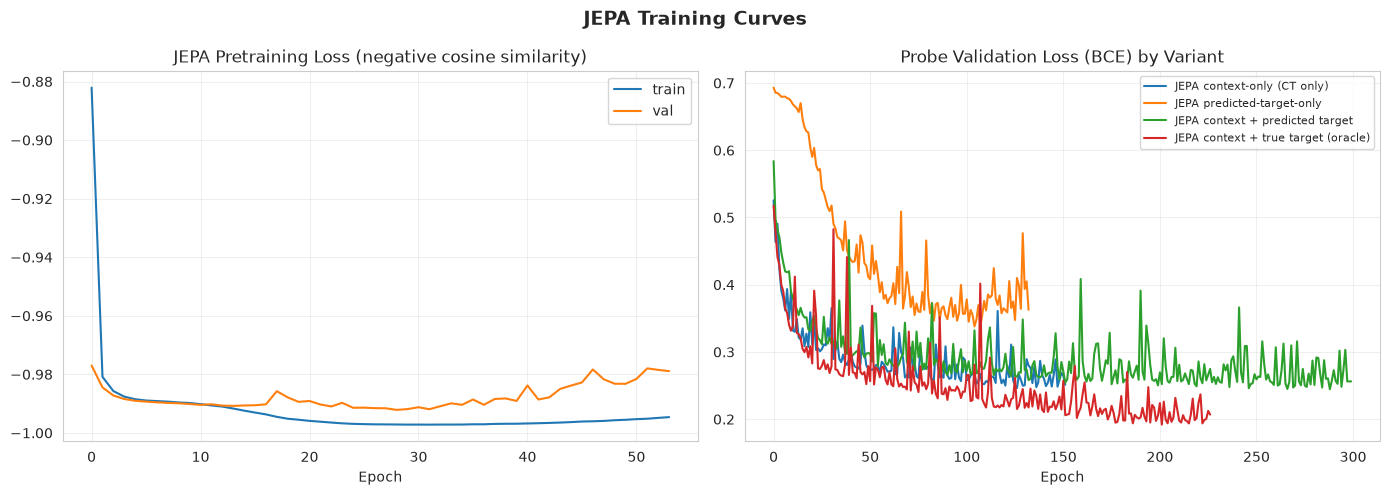

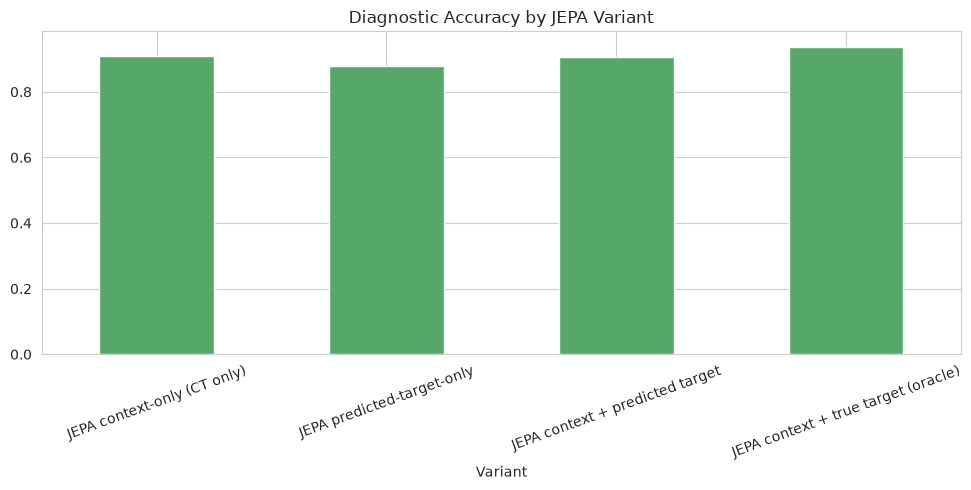

In [ ]:
# ============================================================================
# CELL J4 — TRAINING CURVES
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(pretrain_history["loss"], label="train")
axes[0].plot(pretrain_history["val_loss"], label="val")
axes[0].set_title("JEPA Pretraining Loss (negative cosine similarity)")
axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

for name, hist in jepa_probe_histories.items():
    axes[1].plot(hist["val_loss"], label=name)
axes[1].set_title("Probe Validation Loss (BCE) by Variant")
axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)

plt.suptitle("JEPA Training Curves", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ3_training_curves.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
jepa_df["accuracy"].plot(kind="bar", ax=ax, color="#55A868")
ax.set_title("Diagnostic Accuracy by JEPA Variant"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ3b_variant_bars.png", dpi=180); plt.show()


In [ ]:
# ============================================================================
# CELL J5 — SAVE CHECKPOINTS
# Saved to the SAME CHECKPOINT_DIR the TDN pipeline uses, under a "jepa_"
# prefix, so both sets of weights coexist without collisions.
# ============================================================================
torch.save(jepa.context_enc.state_dict(), f"{CHECKPOINT_DIR}/jepa_context_encoder.pt")
torch.save(jepa.target_enc.state_dict(),  f"{CHECKPOINT_DIR}/jepa_target_encoder.pt")
torch.save(jepa.predictor.state_dict(),   f"{CHECKPOINT_DIR}/jepa_predictor.pt")

for name, state in jepa_probes.items():
    safe = name.replace(" ", "_").replace("(", "").replace(")", "").replace("+", "plus")
    torch.save(state, f"{CHECKPOINT_DIR}/jepa_probe_{safe}.pt")

with open(f"{CHECKPOINT_DIR}/jepa_config.json", "w") as f:
    json.dump({"embed_dim": EMBED_DIM, "base_filters": BASE_FILTERS,
                "ablation_res": ABLATION_RES, "variants": list(jepa_variants.keys())}, f, indent=2)

jepa_df.to_csv(f"{CHECKPOINT_DIR}/tableJ2_jepa_results.csv")
print(f"JEPA checkpoints + results saved to {CHECKPOINT_DIR}")


JEPA checkpoints + results saved to /media/dhrubo/New Volume/TDN/checkpoints


  [aux decoder] epoch 10/30  mse=0.0323
  [aux decoder] epoch 20/30  mse=0.0314
  [aux decoder] epoch 30/30  mse=0.0306


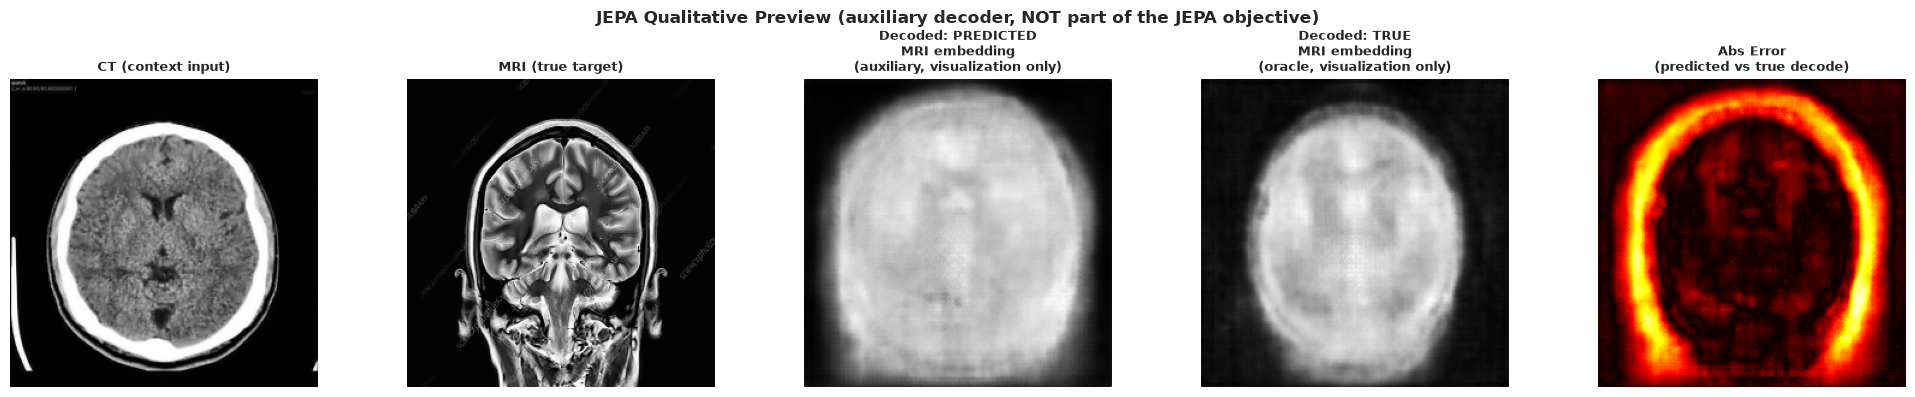

In [ ]:
# ============================================================================
# CELL J6 — AUXILIARY DECODER + QUALITATIVE FIGURE (visualization ONLY)
# This decoder is trained AFTER JEPA pretraining, on DETACHED embeddings
# (.detach() below), purely so we can *look at* what the predicted MRI
# embedding corresponds to in pixel space. It never feeds back into JEPA's
# embeddings, predictor, or probe -- it exists only to produce a qualitative
# figure comparable to TDN's fused-image panel. Report it as such.
# ============================================================================
class AuxDecoder(nn.Module):
    def __init__(self, embed_dim=EMBED_DIM, base_filters=32, out_size=256):
        super().__init__()
        f = base_filters
        self.init_size = out_size // 16  # 4 upsampling stages of x2
        self.fc = nn.Linear(embed_dim, f * 8 * self.init_size * self.init_size)
        self.f8 = f * 8
        self.net = nn.Sequential(
            nn.ConvTranspose2d(f * 8, f * 4, 4, stride=2, padding=1), nn.BatchNorm2d(f*4), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(f * 4, f * 2, 4, stride=2, padding=1), nn.BatchNorm2d(f*2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(f * 2, f,     4, stride=2, padding=1), nn.BatchNorm2d(f),   nn.ReLU(inplace=True),
            nn.ConvTranspose2d(f,     1,     4, stride=2, padding=1), nn.Sigmoid(),
        )

    def forward(self, emb):
        x = self.fc(emb).view(-1, self.f8, self.init_size, self.init_size)
        return self.net(x)


aux_decoder = AuxDecoder(EMBED_DIM, BASE_FILTERS, ABLATION_RES).to(DEVICE)
aux_opt = AdamW(aux_decoder.parameters(), lr=1e-3)

# Quick auxiliary training (visualization only, NOT part of JEPA's objective)
AUX_EPOCHS = 30
n = len(A_tr_t)
for ep in range(AUX_EPOCHS):
    perm = torch.randperm(n)
    ep_losses = []
    for s in range(0, n - n % BATCH_SIZE, BATCH_SIZE):
        idx = perm[s:s + BATCH_SIZE]
        with torch.no_grad():
            target_emb = jepa.embed(A_tr_t[idx], B_tr_t[idx], use_target_true=True)[:, EMBED_DIM:].to(DEVICE)
            true_mri = to_nchw(B_tr[idx.numpy()], DEVICE)
        recon = aux_decoder(target_emb.detach())
        loss = F.mse_loss(recon, true_mri)
        aux_opt.zero_grad(set_to_none=True); loss.backward(); aux_opt.step()
        ep_losses.append(loss.item())
    if (ep + 1) % 10 == 0:
        print(f"  [aux decoder] epoch {ep+1}/{AUX_EPOCHS}  mse={np.mean(ep_losses):.4f}")

# --- Qualitative figure: CT input | true MRI | decoded predicted-MRI-embedding
#     | decoded true-MRI-embedding | abs error map -------------------------
rng = np.random.default_rng(3)
sample_i = int(rng.choice(len(A_te)))

with torch.no_grad():
    emb_pred = jepa.embed(A_te_t[sample_i:sample_i+1], B_te_t[sample_i:sample_i+1],
                           use_target_true=False)[:, EMBED_DIM:].to(DEVICE)
    emb_true = jepa.embed(A_te_t[sample_i:sample_i+1], B_te_t[sample_i:sample_i+1],
                           use_target_true=True)[:, EMBED_DIM:].to(DEVICE)
    decoded_pred = aux_decoder(emb_pred).cpu().numpy()[0, 0]
    decoded_true = aux_decoder(emb_true).cpu().numpy()[0, 0]

ct_img  = A_te[sample_i].squeeze()
mri_img = B_te[sample_i].squeeze()
err_map = np.abs(decoded_pred - decoded_true)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
titles = ["CT (context input)", "MRI (true target)",
          "Decoded: PREDICTED\nMRI embedding\n(auxiliary, visualization only)",
          "Decoded: TRUE\nMRI embedding\n(oracle, visualization only)",
          "Abs Error\n(predicted vs true decode)"]
imgs = [ct_img, mri_img, decoded_pred, decoded_true, err_map]
for ax, img, title in zip(axes, imgs, titles):
    ax.imshow(img, cmap="gray" if title != titles[-1] else "hot")
    ax.set_title(title, fontsize=9, fontweight="bold"); ax.axis("off")
plt.suptitle("JEPA Qualitative Preview (auxiliary decoder, NOT part of the JEPA objective)",
             fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ4_qualitative_preview.png", dpi=200); plt.show()


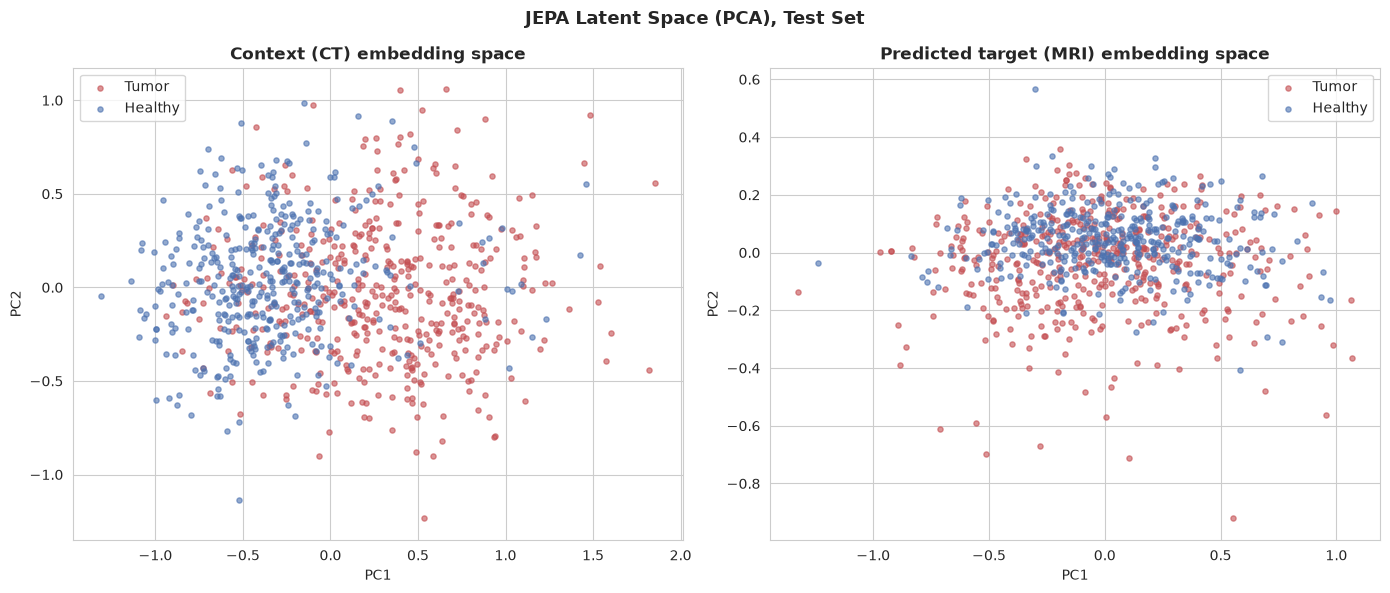

In [ ]:
# ============================================================================
# CELL J7 — EMBEDDING SPACE VISUALIZATION
# JEPA's analogue of TDN's gate-map / alignment figures: instead of a
# pixel-space attention map, we visualize the LATENT SPACE JEPA actually
# operates in, via PCA to 2D, colored by diagnosis.
# ============================================================================
from sklearn.decomposition import PCA

with torch.no_grad():
    ctx_te = jepa.embed(A_te_t, B_te_t, use_context_only=True).numpy()
    full_te = jepa.embed(A_te_t, B_te_t, use_context_only=False).numpy()
    pred_only_te = full_te[:, EMBED_DIM:]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, emb, title in zip(axes, [ctx_te, pred_only_te],
                           ["Context (CT) embedding space", "Predicted target (MRI) embedding space"]):
    coords = PCA(n_components=2, random_state=42).fit_transform(emb)
    for lab, color in [(1, "#C44E52"), (0, "#4C72B0")]:
        m = Y_te.ravel() == lab
        ax.scatter(coords[m, 0], coords[m, 1], s=14, alpha=.6, color=color,
                   label="Tumor" if lab == 1 else "Healthy")
    ax.set_title(title, fontweight="bold"); ax.legend(); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.suptitle("JEPA Latent Space (PCA), Test Set", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ5_embedding_space.png", dpi=200); plt.show()


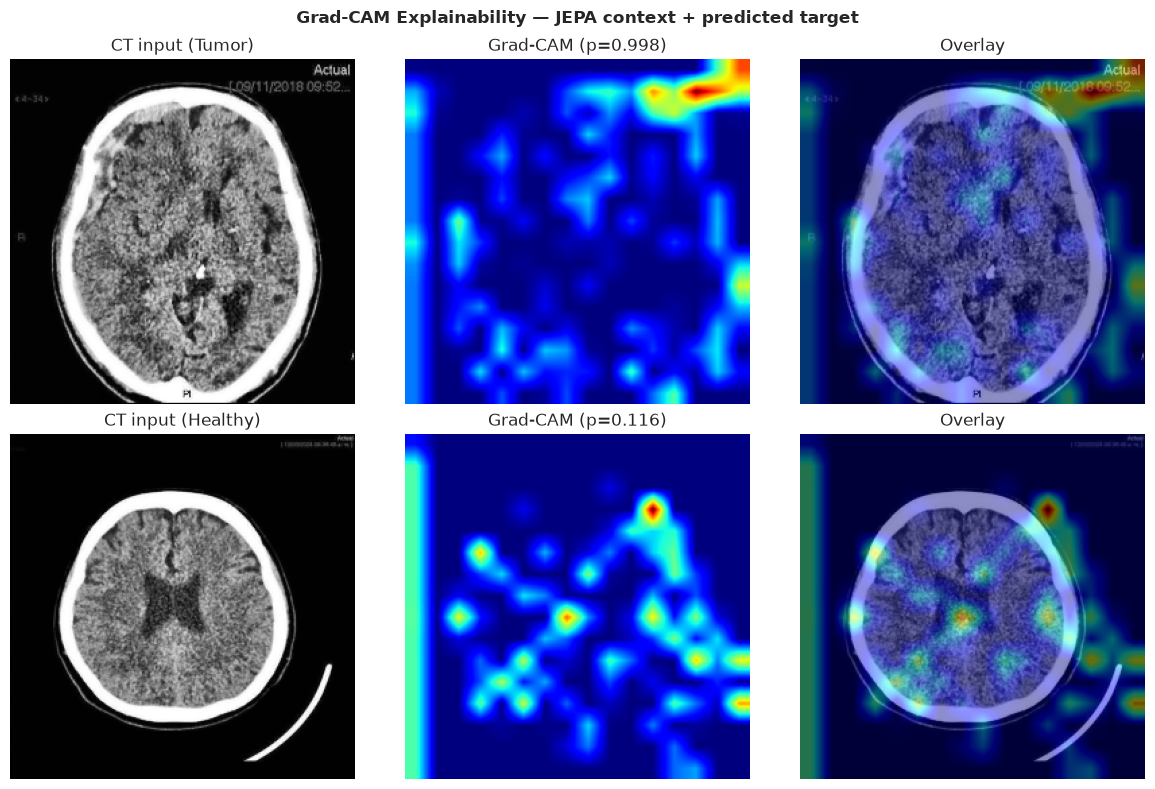

In [ ]:
# ============================================================================
# CELL J8 — GRAD-CAM ON THE CONTEXT ENCODER
# Same idea as TDN's N5 Grad-CAM: backprop the probe's logit to the last
# conv feature map, this time in the CONTEXT ENCODER (since JEPA has no
# single "fused image" to explain). Uses the "context + predicted target"
# probe, the direct analogue of TDN's Full model.
# ============================================================================
FULL_JEPA_KEY = "JEPA context + predicted target"
jepa.probe = Probe(EMBED_DIM * 2).to(DEVICE)
jepa.probe.load_state_dict(jepa_probes[FULL_JEPA_KEY])
jepa.probe.eval()


def jepa_grad_cam(jepa, image_nhwc, device=None):
    device = device or jepa.device
    ctx_enc = jepa.context_enc.eval()
    x = to_nchw(image_nhwc, device)
    with torch.enable_grad():
        fmap = ctx_enc.net(x)
        fmap.retain_grad()
        pooled = ctx_enc.pool(fmap).flatten(1)
        ctx_emb = ctx_enc.proj(pooled)
        pred_emb = jepa.predictor(ctx_emb)
        full_emb = torch.cat([ctx_emb, pred_emb], dim=1)
        logit = jepa.probe(full_emb)
        score = logit.sum()
        grads = torch.autograd.grad(score, fmap)[0]
    pooled_grad = grads.mean(dim=(0, 2, 3))
    heat = (fmap[0].detach() * pooled_grad[:, None, None]).sum(0)
    heat = torch.relu(heat) / (heat.max() + 1e-8)
    return heat.detach().cpu().numpy(), float(torch.sigmoid(logit)[0])


picks = []
for lab, arr in [("Tumor", np.where(Y_te.ravel() == 1)[0]),
                 ("Healthy", np.where(Y_te.ravel() == 0)[0])]:
    if len(arr):
        picks.append((lab, int(arr[0])))

fig, axes = plt.subplots(len(picks), 3, figsize=(12, 4 * len(picks)))
axes = np.atleast_2d(axes)
for r, (lab, i) in enumerate(picks):
    heat, score = jepa_grad_cam(jepa, A_te[i:i+1])
    heat_rs = cv2.resize(heat, (ABLATION_RES, ABLATION_RES))
    ct_img = A_te[i].squeeze()
    axes[r, 0].imshow(ct_img, cmap="gray"); axes[r, 0].set_title(f"CT input ({lab})")
    axes[r, 1].imshow(heat_rs, cmap="jet"); axes[r, 1].set_title(f"Grad-CAM (p={score:.3f})")
    axes[r, 2].imshow(ct_img, cmap="gray"); axes[r, 2].imshow(heat_rs, cmap="jet", alpha=.45)
    axes[r, 2].set_title("Overlay")
    for c in range(3): axes[r, c].axis("off")
plt.suptitle(f"Grad-CAM Explainability — {FULL_JEPA_KEY}", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ6_gradcam.png", dpi=300); plt.show()


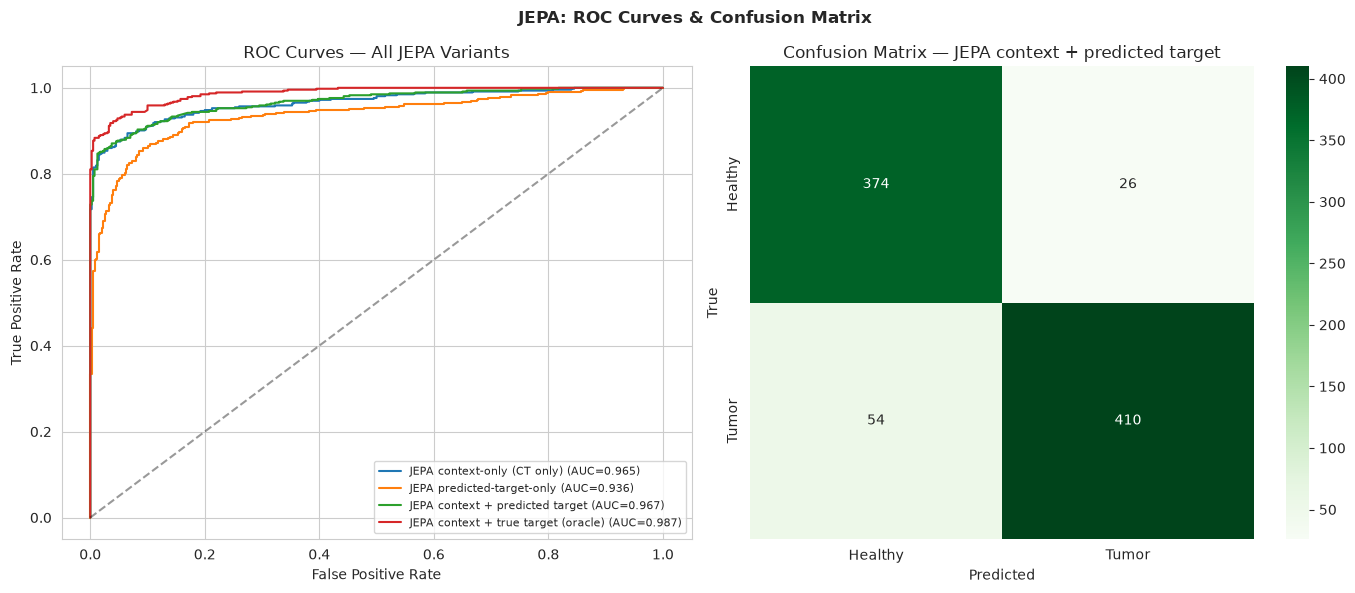

In [ ]:
# ============================================================================
# CELL J9 — ROC CURVES & CONFUSION MATRIX (all JEPA variants)
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, y_prob in jepa_test_probs.items():
    fpr, tpr, _ = roc_curve(Y_te.ravel(), y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves — All JEPA Variants"); axes[0].legend(fontsize=8, loc="lower right")

y_pred_full = (jepa_test_probs[FULL_JEPA_KEY] >= .5).astype(int)
sns.heatmap(confusion_matrix(Y_te.ravel(), y_pred_full, labels=[0, 1]), annot=True, fmt="d",
            cmap="Greens", xticklabels=["Healthy", "Tumor"], yticklabels=["Healthy", "Tumor"],
            ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].set_title(f"Confusion Matrix — {FULL_JEPA_KEY}")
plt.suptitle("JEPA: ROC Curves & Confusion Matrix", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ7_roc_confusion.png", dpi=300); plt.show()


In [ ]:
# # ============================================================================
# # CELL J10 — TDN vs JEPA COMPARISON
# # Loads TDN's saved ablation table (written by TDN's CELL 21 to the SAME
# # CHECKPOINT_DIR) and puts it side-by-side with JEPA's table. If you have not
# # run the TDN notebook in this same CHECKPOINT_DIR yet, this cell will tell
# # you what file is missing instead of failing silently.
# #
# # STATISTICAL SIGNIFICANCE NOTE: a rigorous PAIRED significance test (like
# # TDN's own CELL 28) needs per-sample predictions from BOTH models on the
# # SAME test samples. TDN's notebook does not currently export per-sample
# # test-set predictions to disk (only aggregate metrics), so a paired test
# # across frameworks isn't possible from the saved CSV alone. If you want
# # one, add `np.save(f"{CHECKPOINT_DIR}/tdn_full_test_probs.npy", y_prob)`
# # right after TDN's CELL 18 computes `y_prob` for "Full TDN-Novel", then
# # re-run this cell -- it will pick it up automatically.
# # ============================================================================
# tdn_table_path = f"{CHECKPOINT_DIR}/table2_ablation_results.csv"

# if os.path.exists(tdn_table_path):
#     tdn_df = pd.read_csv(tdn_table_path, index_col=0)
#     print("Loaded TDN results from:", tdn_table_path)

#     common_cols = [c for c in ["accuracy", "precision", "sensitivity", "specificity"] if c in tdn_df.columns]
#     combined = pd.concat([
#         tdn_df[common_cols].assign(Framework="TDN (generative, pixel-space)"),
#         jepa_df[common_cols].assign(Framework="JEPA (non-generative, latent-space)"),
#     ])
#     combined.index.name = "Variant"
#     print("\nTable 5 — TDN vs JEPA, Combined Comparison")
#     print(combined.round(4))
#     combined.to_csv(f"{FIGURE_DIR}/table5_tdn_vs_jepa.csv")

#     fig, ax = plt.subplots(figsize=(12, 6))
#     combined["accuracy"].plot(kind="bar", ax=ax,
#                               color=["#4C72B0" if f.startswith("TDN") else "#55A868"
#                                      for f in combined["Framework"]])
#     ax.set_title("Diagnostic Accuracy: TDN vs JEPA (same test split)", fontweight="bold")
#     ax.tick_params(axis="x", rotation=45, labelsize=8)
#     plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/figJ8_tdn_vs_jepa.png", dpi=200); plt.show()

#     tdn_probs_path = f"{CHECKPOINT_DIR}/tdn_full_test_probs.npy"
#     if os.path.exists(tdn_probs_path):
#         tdn_probs = np.load(tdn_probs_path)
#         jepa_probs = jepa_test_probs[FULL_JEPA_KEY]
#         tdn_correct = (tdn_probs.ravel() >= .5).astype(int) == Y_te.ravel()
#         jepa_correct = (jepa_probs.ravel() >= .5).astype(int) == Y_te.ravel()
#         diff = jepa_correct.astype(float) - tdn_correct.astype(float)
#         t_stat, p_val = stats.ttest_rel(jepa_correct.astype(float), tdn_correct.astype(float))
#         print(f"\nPaired comparison (JEPA full vs TDN full), n={len(diff)}: "
#               f"mean_diff={diff.mean():.4f}  t={t_stat:.4f}  p={p_val:.4e}")
#     else:
#         print(f"\nNo per-sample TDN test predictions found at {tdn_probs_path} -- "
#               f"skipping paired significance test (see note above to enable it).")
# else:
#     print(f"TDN results not found at {tdn_table_path}.")
#     print("Run the TDN notebook first (with the SAME CHECKPOINT_DIR), then re-run this cell.")
#     print("\nJEPA-only results:")
#     print(jepa_df)


In [ ]:
# ============================================================================
# CELL J11 — EXPORT INVENTORY
# ============================================================================
jepa_df.to_csv(f"{FIGURE_DIR}/tableJ2_jepa_results.csv")

print("Tables:")
for f in sorted(os.listdir(FIGURE_DIR)):
    if f.endswith(".csv"): print("  -", f)
print("\nFigures (figJ* = JEPA, fig* = TDN if present in the same FIGURE_DIR):")
for f in sorted(os.listdir(FIGURE_DIR)):
    if f.endswith(".png"): print("  -", f)
print(f"\nJEPA pipeline complete. Everything in {FIGURE_DIR}")


Tables:
  - tableJ2_jepa_results.csv

Figures (figJ* = JEPA, fig* = TDN if present in the same FIGURE_DIR):
  - fig1a_class_balance.png
  - fig1b_preprocessing.png
  - fig1c_histograms.png
  - fig1d_sample_pairs.png
  - figJ3_training_curves.png
  - figJ3b_variant_bars.png
  - figJ4_qualitative_preview.png
  - figJ5_embedding_space.png
  - figJ6_gradcam.png
  - figJ7_roc_confusion.png

JEPA pipeline complete. Everything in /media/dhrubo/New Volume/TDN/paper_figures


In [ ]:
# ============================================================================
# CELL J12 — GPU CLEANUP
# ============================================================================
for _name in ["jepa", "aux_decoder", "jepa_probes"]:
    if _name in globals():
        try:
            del globals()[_name]
        except Exception:
            pass
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    for i in range(torch.cuda.device_count()):
        free, total = torch.cuda.mem_get_info(i)
        alloc = torch.cuda.memory_allocated(i) // 1024**2
        reserv = torch.cuda.memory_reserved(i) // 1024**2
        print(f"cuda:{i} free={free//1024**2}MB/{total//1024**2}MB "
              f"| torch allocated={alloc}MB reserved={reserv}MB")
else:
    print("No CUDA device.")


cuda:0 free=23033MB/24117MB | torch allocated=0MB reserved=0MB
cuda:1 free=23341MB/24126MB | torch allocated=343MB reserved=390MB
